# EEEM030 Group Assignment 2: Speech Recognition

Isolated-word recognition (11 words) with an FFN and a Transformer.

**Team members / chapter authors:** _TBC_

## 0. Setup

### 0.1 Imports

In [51]:
from pathlib import Path
from collections import Counter
from io import BytesIO
import hashlib
import json
import math
import platform
import time
import urllib.request
import zipfile

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import soundfile as sf
import torch
import torchaudio
from torch import nn
from IPython.display import Audio, Markdown, display

SEED = 30
torch.manual_seed(SEED)
torch.set_num_threads(2)  # Small CPU operations do not need many threads.
DTYPE = torch.float32
DEVICE = torch.device('cpu')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})

print('Python:', platform.python_version())
print('PyTorch:', torch.__version__, '| TorchAudio:', torchaudio.__version__)
print('Device:', DEVICE, '| dtype:', DTYPE, '| seed:', SEED)


def parse_recording(path):
    speaker, recording, word = path.stem.split('_')

    return {
        'path': path,
        'speaker': speaker,
        'recording': int(recording[1:]),
        'word': word
    }

paths = sorted(Path("DevelopmentSet").glob("*.mp3"))

records = [parse_recording(path) for path in paths]

# Speakers list
all_speakers = sorted({r['speaker'] for r in records})

# Words list
all_words = sorted({r['word'] for r in records})

print("Speakers:", all_speakers)
print("Words:", all_words)

# Nbr of recordings
print("Total recordings:", len(records))

counts = Counter((r['speaker'], r['word']) for r in records)

print("Recordings per speaker:", set(counts.values()))

Python: 3.11.9
PyTorch: 2.6.0+cpu | TorchAudio: 2.6.0+cpu
Device: cpu | dtype: torch.float32 | seed: 30
Speakers: ['sp01a', 'sp02a', 'sp03a', 'sp04a', 'sp05a', 'sp06a', 'sp07a', 'sp08a', 'sp09a', 'sp10a', 'sp11a', 'sp12a', 'sp13a', 'sp14a', 'sp15a', 'sp16a', 'sp17a', 'sp18a', 'sp19a', 'sp20a', 'sp21a', 'sp22a', 'sp23a', 'sp24a', 'sp25a', 'sp26a', 'sp27a', 'sp28a', 'sp29a', 'sp30a']
Words: ['had', 'hard', 'head', 'heard', 'heed', 'hid', 'hoard', 'hod', 'hood', 'hud', 'whod']
Total recordings: 330
Recordings per speaker: {1}


Training, validation and test set

In [52]:
TRAIN_SPEAKERS = {'sp01a', 'sp02a', 'sp03a', 'sp04a', 'sp05a', 'sp06a', 'sp07a', 'sp08a', 'sp09a', 'sp10a',
                  'sp11a', 'sp12a', 'sp13a', 'sp14a', 'sp15a', 'sp16a', 'sp17a', 'sp18a', 'sp19a', 'sp20a',
                  'sp21a', 'sp22a', 'sp23a', 'sp24a', 'sp25a', 'sp26a', 'sp27a', 'sp28a'}
VAL_SPEAKERS = {'sp29a'}
TEST_SPEAKERS = {'sp30a'}

# Training speakers must not appear in validation or test.
assert TRAIN_SPEAKERS.isdisjoint(VAL_SPEAKERS | TEST_SPEAKERS)

# Validation and test speakers must not overlap.
assert VAL_SPEAKERS.isdisjoint(TEST_SPEAKERS)

# The three splits must collectively contain exactly the dataset's speakers.
assert TRAIN_SPEAKERS | VAL_SPEAKERS | TEST_SPEAKERS == set(all_speakers)

split_speakers = {'train': TRAIN_SPEAKERS, 'validation': VAL_SPEAKERS, 'test': TEST_SPEAKERS}
split_indices = {
    split: torch.tensor([i for i, r in enumerate(records) if r['speaker'] in speakers],
                        dtype=torch.long)
    for split, speakers in split_speakers.items()
}
for split, indices in split_indices.items():
    labels = Counter(records[i]['word'] for i in indices.tolist())
    print(f'{split:<11}: {len(indices):4d} recordings | per-word counts: {dict(sorted(labels.items()))}')
    # Check that the split contains all eleven word labels with no other labels.
    assert set(labels) == set(all_words)


train      :  308 recordings | per-word counts: {'had': 28, 'hard': 28, 'head': 28, 'heard': 28, 'heed': 28, 'hid': 28, 'hoard': 28, 'hod': 28, 'hood': 28, 'hud': 28, 'whod': 28}
validation :   11 recordings | per-word counts: {'had': 1, 'hard': 1, 'head': 1, 'heard': 1, 'heed': 1, 'hid': 1, 'hoard': 1, 'hod': 1, 'hood': 1, 'hud': 1, 'whod': 1}
test       :   11 recordings | per-word counts: {'had': 1, 'hard': 1, 'head': 1, 'heard': 1, 'heed': 1, 'hid': 1, 'hoard': 1, 'hod': 1, 'hood': 1, 'hud': 1, 'whod': 1}


Focus on one waveform

Filename: sp05a_w05_hard.mp3
Waveform shape: (11520,) | duration: 0.72 s


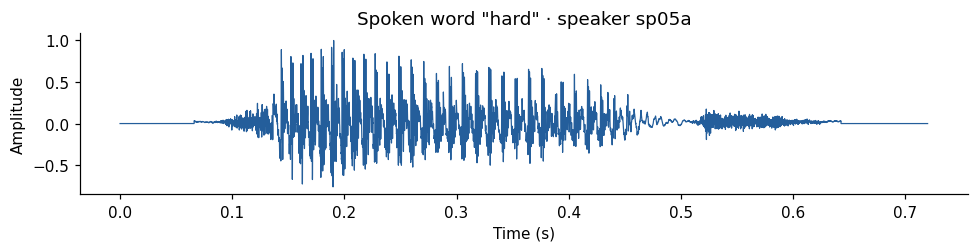

In [53]:
SAMPLE_RATE = 16000

def load_waveform(path):
    samples, sample_rate = sf.read(str(path), dtype='float32', always_2d=True)
    waveform = torch.from_numpy(samples).mean(dim=1).contiguous()  # (N,), mono
    if sample_rate != SAMPLE_RATE:
        raise ValueError(f'{path.name}: expected {SAMPLE_RATE} Hz; got {sample_rate} Hz.')
    if waveform.numel() == 0 or not torch.isfinite(waveform).all():
        raise ValueError(f'{path.name}: empty or non-finite waveform.')
    return waveform

example_record = next(r for r in records if r['word'] == 'hard' and r['speaker'] == 'sp05a')
waveform = load_waveform(example_record['path'])
time_axis = torch.arange(waveform.numel()) / SAMPLE_RATE
print('Filename:', example_record['path'].name)
print('Waveform shape:', tuple(waveform.shape), '| duration:', round(len(waveform) / SAMPLE_RATE, 3), 's')
fig, ax = plt.subplots(figsize=(9, 2.4))
ax.plot(time_axis, waveform, linewidth=0.8, color='#245e9b')
ax.set(xlabel='Time (s)', ylabel='Amplitude', title='Spoken word "hard" · speaker sp05a')
fig.tight_layout()
plt.show()
display(Audio(waveform.numpy(), rate=SAMPLE_RATE))


Log-mel spectrogram 

In [54]:
N_MELS = 80
WIN_LENGTH = round(0.025 * SAMPLE_RATE)  # 200
HOP_LENGTH = round(0.010 * SAMPLE_RATE)  # 80
N_FFT = 512

mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=SAMPLE_RATE, n_fft=N_FFT, win_length=WIN_LENGTH,
    hop_length=HOP_LENGTH, f_min=0.0, f_max=SAMPLE_RATE / 2,
    n_mels=N_MELS, power=2.0, center=True, pad_mode='constant',
    norm='slaney', mel_scale='slaney',
)

def log_mel_spectrogram(waveform):
    mel_power = mel_transform(waveform)                    # (80, T)
    log_power = 10.0 * torch.log10(mel_power.clamp_min(1e-10))
    log_mel = (log_power - log_power.max()).clamp_min(-80.0)
    assert log_mel.ndim == 2 and log_mel.shape[0] == N_MELS
    assert torch.isfinite(log_mel).all()
    return log_mel

example_log_mel = log_mel_spectrogram(waveform)
print('Log-mel (F, T):', tuple(example_log_mel.shape))
print('A single frame:', tuple(example_log_mel[:, 0].shape))
print('Range (relative dB):', float(example_log_mel.min()), 'to', float(example_log_mel.max()))


Log-mel (F, T): (80, 73)
A single frame: (80,)
Range (relative dB): -80.0 to 0.0


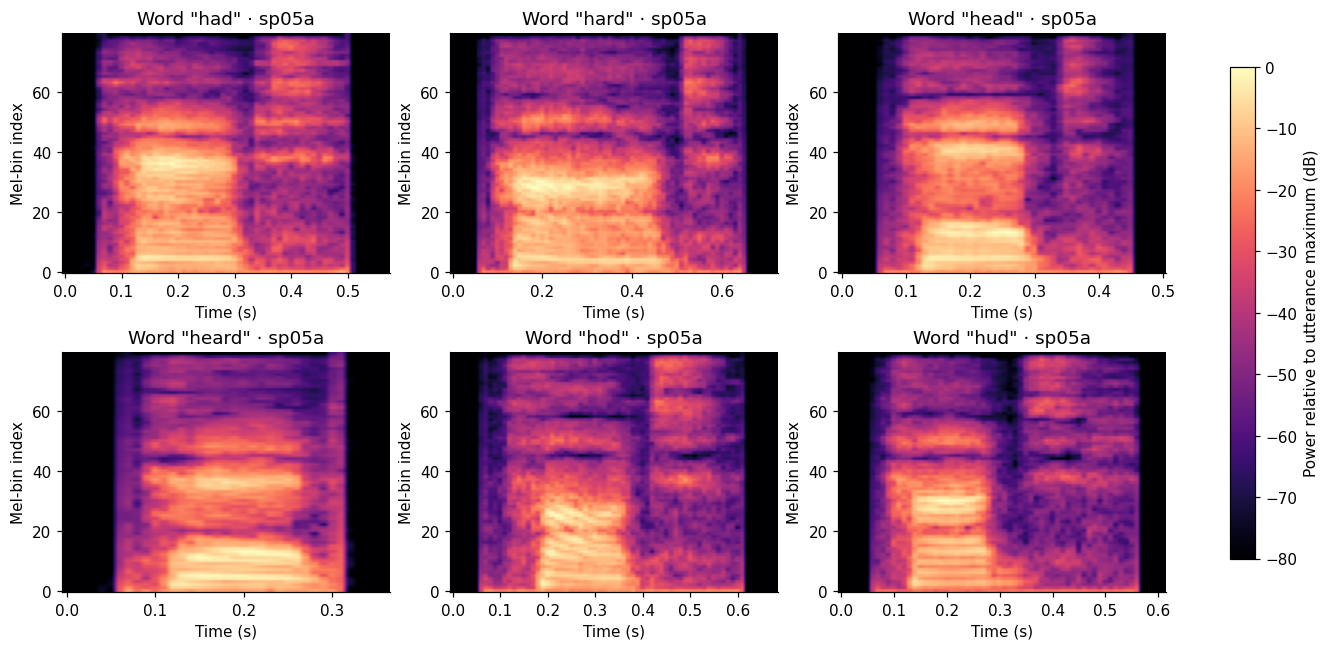

In [55]:
# Six training examples; validation and test examples are not used for visual choices.
fig, axes = plt.subplots(2, 3, figsize=(12, 5.8), layout='constrained')
for nbr, ax in zip([0, 1, 2, 3, 7, 9], axes.flat):
    record = next(r for r in records if r['word'] == all_words[nbr] and r['speaker'] == 'sp05a')
    mel = log_mel_spectrogram(load_waveform(record['path']))
    # With centred frames, frame centres are at t * hop / sample_rate.
    half_hop = HOP_LENGTH / (2 * SAMPLE_RATE)
    end = (mel.shape[1] - 1) * HOP_LENGTH / SAMPLE_RATE + half_hop
    image = ax.imshow(mel.numpy(), origin='lower', aspect='auto', cmap='magma',
                      vmin=-80, vmax=0, extent=(-half_hop, end, -0.5, N_MELS - 0.5))
    ax.set(title=f'Word "{all_words[nbr]}" · sp05a', xlabel='Time (s)', ylabel='Mel-bin index')
fig.colorbar(image, ax=axes, label='Power relative to utterance maximum (dB)', shrink=0.88)
plt.show()

Mean pooling for each mel spectrogram ==> (80,1) vectors

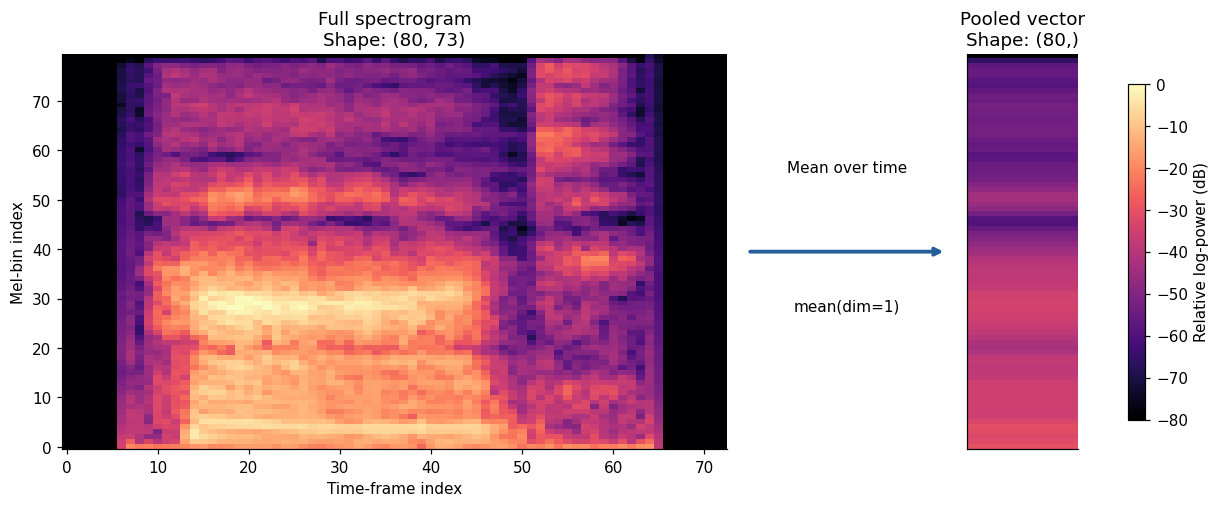

Before pooling: (80, 73) | after: (80,)


In [56]:
# Average over time, retaining one value per mel bin.
pooled_example = example_log_mel.mean(dim=1)
assert pooled_example.shape == (80,)

fig = plt.figure(figsize=(11, 4.5), layout='constrained')
grid = fig.add_gridspec(1, 3, width_ratios=[6, 2, 1])

ax_spec = fig.add_subplot(grid[0, 0])
ax_arrow = fig.add_subplot(grid[0, 1])
ax_vector = fig.add_subplot(grid[0, 2], sharey=ax_spec)

# A shared colour scale makes the two representations comparable.
colour_settings = dict(
    origin='lower',
    aspect='auto',
    cmap='magma',
    vmin=-80,
    vmax=0,
    interpolation='nearest',
)

# Full spectrogram: (80, T)
image = ax_spec.imshow(
    example_log_mel.detach().cpu().numpy(),
    **colour_settings,
)
ax_spec.set(
    title=f'Full spectrogram\nShape: {tuple(example_log_mel.shape)}',
    xlabel='Time-frame index',
    ylabel='Mel-bin index',
)

# Arrow showing the pooling operation.
ax_arrow.set_axis_off()
ax_arrow.annotate(
    '',
    xy=(0.95, 0.5),
    xytext=(0.05, 0.5),
    xycoords='axes fraction',
    arrowprops=dict(arrowstyle='->', lw=2.5, color='#245e9b'),
)
ax_arrow.text(
    0.5, 0.70, 'Mean over time',
    ha='center', transform=ax_arrow.transAxes,
)
ax_arrow.text(
    0.5, 0.35, 'mean(dim=1)',
    ha='center', transform=ax_arrow.transAxes,
)

# Pooled vector: (80,), displayed as an (80, 1) column.
ax_vector.imshow(
    pooled_example.detach().cpu().numpy()[:, None],
    **colour_settings,
)
ax_vector.set(
    title=f'Pooled vector\nShape: {tuple(pooled_example.shape)}',
    xticks=[],
)
ax_vector.tick_params(axis='y', left=False, labelleft=False)

fig.colorbar(
    image,
    ax=[ax_spec, ax_vector],
    label='Relative log-power (dB)',
    shrink=0.85,
)

plt.show()

print(
    'Before pooling:', tuple(example_log_mel.shape),
    '| after:', tuple(pooled_example.shape),
)

In [57]:
# Shape notation:
# B = number of recordings, F = number of mel bins (80)
# T_i = number of time frames in recording i (varies between recordings)

start_time = time.perf_counter()
sequences = []
pooled_vectors = []

for i, record in enumerate(records):
    # Shape: (F, T_i) — mel bins × time frames
    log_mel = log_mel_spectrogram(load_waveform(record['path']))

    # Shape: (T_i, F) — time frames × mel bins
    sequences.append(log_mel.T.contiguous())

    # Shape: (F,) — one average value per mel bin, pooled over time
    pooled_vectors.append(log_mel.mean(dim=1))

    if (i + 1) % 1000 == 0:
        print(f'Processed {i + 1}/{len(records)} recordings')

# Shape: (B, F) = (330, 80) — recordings × pooled mel features
X_raw = torch.stack(pooled_vectors).to(dtype=DTYPE)

# Shape: (B,) = (330,) — one digit label per recording
# Create a mapping between words and integer labels
word_to_label = {word: i for i, word in enumerate(all_words)}
print([(all_words[i], i) for i in range(len(all_words))])
y_all = torch.tensor(
    [word_to_label[r['word']] for r in records],
    dtype=torch.long,
)

assert X_raw.shape == (330, 80) and y_all.shape == (330,)
assert torch.isfinite(X_raw).all()

# Shape: (B,) — number of time frames in each recording
lengths = torch.tensor([sequence.shape[0] for sequence in sequences])

print(f'Feature extraction took {time.perf_counter() - start_time:.1f} s')
print('X_raw (recordings, mel features):', X_raw.shape)
print('Labels (recordings,):', y_all.shape)
print(
    'Time frames per recording: min / median / max =',
    lengths.min().item(),
    lengths.median().item(),
    lengths.max().item(),
)

[('had', 0), ('hard', 1), ('head', 2), ('heard', 3), ('heed', 4), ('hid', 5), ('hoard', 6), ('hod', 7), ('hood', 8), ('hud', 9), ('whod', 10)]
Feature extraction took 0.6 s
X_raw (recordings, mel features): torch.Size([330, 80])
Labels (recordings,): torch.Size([330])
Time frames per recording: min / median / max = 33 55 83


Standardize

In [58]:
train_indices = split_indices['train']
feature_mean = X_raw[train_indices].mean(dim=0, keepdim=True)  # (1, 80)
feature_std = X_raw[train_indices].std(dim=0, unbiased=False, keepdim=True).clamp_min(1e-5)

assert X_raw.shape == (330, 80)
assert feature_mean.shape == (1, 80), feature_mean.shape
assert feature_std.shape == (1,80), feature_std.shape

X_all = (X_raw - feature_mean) / feature_std

X_train, y_train = X_all[train_indices], y_all[train_indices]
X_val, y_val = X_all[split_indices['validation']], y_all[split_indices['validation']]
X_test, y_test = X_all[split_indices['test']], y_all[split_indices['test']]


assert X_train.shape == (308, 80) and X_val.shape == X_test.shape == (11, 80)
assert torch.isfinite(X_all).all()
assert X_train.mean(dim=0).abs().max() < 1e-4
assert (X_train.std(dim=0, unbiased=False) - 1).abs().max() < 1e-4
print('Training mean, first five features:', X_train.mean(dim=0)[:5])
print('Training std, first five features: ', X_train.std(dim=0, unbiased=False)[:5])
print('Prepared tensors: X_train, y_train; X_val, y_val; X_test, y_test\n')
print('---\n\nShapes:\n- Training set: X_train(recordings, mel features):', X_train.shape, ', y_train(recordings,):', y_train.shape)
print('- Validation set: X_val(recordings, mel features):', X_val.shape, ', y_val(recordings,):', y_val.shape)
print('- Test set: X_test(recordings, mel features):', X_test.shape, ', y_test(recordings,):', y_test.shape)


Training mean, first five features: tensor([ 4.6445e-07, -4.7684e-07, -5.8056e-07, -7.8338e-07, -4.2420e-07])
Training std, first five features:  tensor([1., 1., 1., 1., 1.])
Prepared tensors: X_train, y_train; X_val, y_val; X_test, y_test

---

Shapes:
- Training set: X_train(recordings, mel features): torch.Size([308, 80]) , y_train(recordings,): torch.Size([308])
- Validation set: X_val(recordings, mel features): torch.Size([11, 80]) , y_val(recordings,): torch.Size([11])
- Test set: X_test(recordings, mel features): torch.Size([11, 80]) , y_test(recordings,): torch.Size([11])


The different sets are ready to be used. Each tensor X contains vectors with dimensions (80,). These vectors are time-averaged representations of the mel-spectrograms for each audio file. The lists Y contain the corresponding words. Three sets are available:
- training set, speaker 1 to 28 : X_train, y _train
- validation, speaker 29: X_val, y_val
- test set, speaker 30: X_test, y_test

Regarding tensors y, here is the correspondence between the words and the numbers:

0='had', 1='hard', 2='head', 3='heard', 4='heed', 5='hid', 6='hoard', 7='hod', 8='hood', 9='hud', 10='whod'


### 0.2 Environment specification & random seeds

### 0.3 Global hyper-parameters / config

## Part 2: Data Preparation & Feed-Forward Network

### 2.1 Load speech recordings & parse labels

### 2.2 Log-mel spectrogram extraction (80 mel bins, 25 ms window, 10 ms hop)

### 2.3 Fixed-length representation (pooling / pad-truncate / sequence)

### 2.4 Train / validation / test split (speaker-independent)

### 2.5 Plot example mel-spectrograms with labels

### 2.6 MLP from scratch (NumPy): forward pass

In [ ]:
import numpy as np

INPUT_DIM = X_train.shape[1] 
HIDDEN_DIMS = (64, 32)
NUM_CLASSES = len(all_words)            
LAYER_DIMS = (INPUT_DIM, *HIDDEN_DIMS, NUM_CLASSES)


def relu(z):
    return np.maximum(z, 0.0)


def log_softmax(z):
    z_shift = z - z.max(axis=-1, keepdims=True)
    return z_shift - np.log(np.exp(z_shift).sum(axis=-1, keepdims=True))


def softmax(z):
    return np.exp(log_softmax(z))


class NumpyMLP:
    def __init__(self, layer_dims, seed=SEED, dtype=np.float64):
        rng = np.random.default_rng(seed)
        self.layer_dims = tuple(layer_dims)
        self.W, self.b = [], []
        for d_in, d_out in zip(self.layer_dims[:-1], self.layer_dims[1:]):
            # He initialisation for ReLU
            self.W.append((rng.standard_normal((d_out, d_in)) * np.sqrt(2.0 / d_in)).astype(dtype))
            self.b.append(np.zeros(d_out, dtype=dtype))

    @property
    def num_parameters(self):
        return sum(W.size + b.size for W, b in zip(self.W, self.b))

    def forward(self, X, return_cache=False):
        single = X.ndim == 1
        h = X[None, :] if single else X                # (B, 80)
        cache = {'h': [h], 'z': []}
        n_layers = len(self.W)
        for l, (W, b) in enumerate(zip(self.W, self.b), start=1):
            z = h @ W.T + b                            # (B, d_l)
            cache['z'].append(z)
            h = relu(z) if l < n_layers else z         # hidden: ReLU; output: linear logits
            cache['h'].append(h)
        cache['logits'] = h                            # (B, 11)
        probs = softmax(h)                             # (B, 11); each row sums to 1
        if single:
            probs = probs[0]
        return (probs, cache) if return_cache else probs

In [ ]:
np_mlp = NumpyMLP(LAYER_DIMS)
X_train_np = X_train.numpy().astype(np.float64)        # (308, 80)

# Dimension counting, checked against the table above.
print('Layer dims:', LAYER_DIMS)
for l, (W, b) in enumerate(zip(np_mlp.W, np_mlp.b), start=1):
    print(f'  Layer {l}: W{l} {W.shape}, b{l} {b.shape} -> {W.size + b.size:,} parameters')
expected = sum(d_in * d_out + d_out for d_in, d_out in zip(LAYER_DIMS[:-1], LAYER_DIMS[1:]))
assert np_mlp.num_parameters == expected
print(f'Total parameters: {np_mlp.num_parameters:,}')

# Forward pass on the whole training set.
probs_np, cache_np = np_mlp.forward(X_train_np, return_cache=True)
print('\nForward pass, batch of training vectors:')
print('  input  h0:', cache_np['h'][0].shape)
for l, z in enumerate(cache_np['z'], start=1):
    print(f'  layer {l} z{l}:', z.shape)
print('  softmax  :', probs_np.shape)

assert probs_np.shape == (len(X_train_np), NUM_CLASSES)
assert np.allclose(probs_np.sum(axis=1), 1.0)          # valid distributions
assert np.isfinite(probs_np).all() and (probs_np > 0).all()

# Untrained, so accuracy should be close to chance (1/11, about 9%).
untrained_acc = (probs_np.argmax(axis=1) == y_train.numpy()).mean()
print(f'\nUntrained training accuracy: {untrained_acc:.1%} (chance = {1 / NUM_CLASSES:.1%})')

### 2.7 MLP in PyTorch (`nn.Module`)

### 2.8 Worked numerical check: NumPy vs PyTorch outputs

### 2.9 Shape diagram / dimension counting

## Part 3: Training with Backpropagation & SGD

### 3.1 NumPy MLP: backpropagation by hand

#### 3.1.1 Gradient derivation (cross-entropy + softmax, chain rule)

#### 3.1.2 Backward pass implementation

#### 3.1.3 Vanilla SGD / mini-batch training loop

#### 3.1.4 Loss & accuracy tracking (train / validation)

### 3.2 PyTorch MLP training

#### 3.2.1 Training with `torch.optim.SGD`

#### 3.2.2 Training with Adam

#### 3.2.3 Regularisation: weight decay & dropout

#### 3.2.4 Augmentation: SpecAugment / additive noise

### 3.3 Learning-rate schedules & early stopping

### 3.4 Results: loss & accuracy curves

### 3.5 Comparison table (accuracy, confusion matrix, parameters, training time)

### 3.6 Discussion: effect of dropout / SpecAugment on train–validation gap

## Part 4: Attention Mechanism

### 4.1 Scaled dot-product attention (from scratch)

### 4.2 Multi-head attention

### 4.3 Worked example: 4–8 frame toy sequence (Q, K, V, weights, output)

### 4.4 Verification against implementation

### 4.5 Self-attention on mel-spectrogram frames

### 4.6 Attention weight visualisations & interpretation

## Part 5: Basic Transformer Encoder for Mel-Spectrograms

### 5.1 Positional encodings (sinusoidal / learned)

### 5.2 Convolutional subsampling front-end (optional)

### 5.3 Transformer encoder block (MHSA + residual + LayerNorm, FFN + residual + LayerNorm)

### 5.4 Full model: 2 stacked encoder layers + classification head

### 5.5 Training & inference methods

### 5.6 Training curves & final test accuracy

### 5.7 Comparison vs MLP (accuracy & parameter count)

### 5.8 Analysis: does attention help? Effect of sequence length after subsampling

## Final Evaluation on Test Data

## Discussion Questions

### Why is the data-driven approach particularly powerful for speech?

### How does the √d_k scaling prevent vanishing gradients in the softmax?

### FFN on pooled features vs Transformer on full sequence: trade-offs

## Stretch Objectives (optional)

## References & Third-Party Code Attribution